In [3]:
import kagglehub
import pandas as pd
from pathlib import Path
from pymongo import MongoClient
from datetime import datetime
from ipywidgets import FileUpload
from PIL import Image
import io
from google import genai
from dotenv import load_dotenv
load_dotenv()
import os
import json

In [ ]:
path = kagglehub.dataset_download("prasad22/daily-transactions-dataset")

print("Path to dataset files:", path)

c:\Users\Tenzin Choeyang D\OneDrive\Desktop\expenses-mongodb\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Tenzin Choeyang D\.cache\kagglehub\datasets\prasad22\daily-transactions-dataset\versions\4


In [ ]:
BASE_DIR=Path("C:/Users/Tenzin Choeyang D/OneDrive/Desktop/expenses-mongodb")
INPUT_FILE=BASE_DIR/"data"/"raw"/"Daily Household Transactions.csv"
OUTPUT_FILE=BASE_DIR/"data"/"processed"/"transactions_cleaned.csv"

df=pd.read_csv(INPUT_FILE)
print("Original Data:")
print(df.head())
print("\nShape: ",df.shape)

Original Data:
                  Date                   Mode        Category  \
0  20/09/2018 12:04:08                   Cash  Transportation   
1  20/09/2018 12:03:15                   Cash            Food   
2           19/09/2018  Saving Bank account 1    subscription   
3  17/09/2018 23:41:17  Saving Bank account 1    subscription   
4  16/09/2018 17:15:08                   Cash       Festivals   

               Subcategory                         Note  Amount  \
0                    Train         2 Place 5 to Place 0    30.0   
1                   snacks  Idli medu Vada mix 2 plates    60.0   
2                  Netflix         1 month subscription   199.0   
3  Mobile Service Provider            Data booster pack    19.0   
4             Ganesh Pujan                  Ganesh idol   251.0   

  Income/Expense Currency  
0        Expense      INR  
1        Expense      INR  
2        Expense      INR  
3        Expense      INR  
4        Expense      INR  

Shape:  (2461, 8)


In [3]:
df=df.drop_duplicates()
df.columns=(
    df.columns
    .str.strip()
    .str.lower()
    .str.replace("/","_")
    .str.replace(" ","_")
)

df["date"]=pd.to_datetime(df["date"],errors="coerce")
df["amount"]=pd.to_numeric(df["amount"],errors="coerce")
df["category"] = (
    df["category"]
    .str.strip()
    .str.lower()
)

df["subcategory"] = (
    df["subcategory"]
    .str.strip()
    .str.lower()
)

df=df.dropna(subset=["date","amount","category"])
df = df.where(pd.notna(df), None)

df.insert(0,"transaction_id",["TXN" + str(i).zfill(4) for i in range(1, len(df) + 1)])
print("Cleaned Data:")
print(df.head())
print("\nShape: ",df.shape)


Cleaned Data:
  transaction_id                date                   mode        category  \
0        TXN0001 2018-09-20 12:04:08                   Cash  transportation   
1        TXN0002 2018-09-20 12:03:15                   Cash            food   
3        TXN0003 2018-09-17 23:41:17  Saving Bank account 1    subscription   
4        TXN0004 2018-09-16 17:15:08                   Cash       festivals   
5        TXN0005 2018-09-15 06:34:17            Credit Card    subscription   

               subcategory                                      note  amount  \
0                    train                      2 Place 5 to Place 0    30.0   
1                   snacks               Idli medu Vada mix 2 plates    60.0   
3  mobile service provider                         Data booster pack    19.0   
4             ganesh pujan                               Ganesh idol   251.0   
5                 tata sky  Permanent Residence - Tata Play recharge   200.0   

  income_expense currency  
0 

C:\Users\Tenzin Choeyang D\AppData\Local\Temp\ipykernel_23948\270560109.py:10: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["date"]=pd.to_datetime(df["date"],errors="coerce")


In [4]:
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_FILE, index=False)

In [4]:
client=MongoClient("mongodb://127.0.0.1:27017/")
db=client["expense_db"]
if "transactions" not in db.list_collection_names():
    db.create_collection(
        "transactions",
        validator={
            "$jsonSchema": {
                "bsonType": "object",
                "required": [
                    "date",
                    "mode",
                    "category",
                    "amount",
                    "income_expense",
                    "currency"
                ],
                "properties": {
                    "date": {
                        "bsonType": "date"
                    },
                    "mode": {
                        "bsonType": "string"
                    },
                    "category": {
                        "bsonType": "string"
                    },
                    "subcategory": {
                        "bsonType": ["string", "null"]
                    },
                    "note": {
                        "bsonType": ["string", "null"]
                    },
                    "amount": {
                        "bsonType": ["double", "int", "long"],
                        "minimum": 0
                    },
                    "income_expense": {
                        "enum": ["Income", "Expense"]
                    },
                    "currency": {
                        "enum": ["INR"]
                    }
                }
            }
        }
    )
collection=db["transactions"]

In [14]:
records=df.to_dict(orient="records")
collection.insert_many(records)

NameError: name 'df' is not defined

In [ ]:
expense = {
    "transaction_id": "TXN0008",
    "date": datetime(2026, 9, 15),
    "mode": "UPI",
    "category": "Food",
    "subcategory": "Pizza",
    "note": "Dominos",
    "amount": 450.0,
    "income_expense": "Expense",
    "currency": "INR"
}

collection.insert_one(expense)

InsertOneResult(ObjectId('6ab0c9a1f56bd860021fdd4c'), acknowledged=True)

In [3]:
for transaction in collection.find():
    print(transaction)

{'_id': ObjectId('6aaa76b0b9f553990a97e516'), 'transaction_id': 'TXN0001', 'date': datetime.datetime(2018, 9, 20, 12, 4, 8), 'mode': 'Cash', 'category': 'transportation', 'subcategory': 'train', 'note': '2 Place 5 to Place 0', 'amount': 30.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e517'), 'transaction_id': 'TXN0002', 'date': datetime.datetime(2018, 9, 20, 12, 3, 15), 'mode': 'Cash', 'category': 'food', 'subcategory': 'snacks', 'note': 'Idli medu Vada mix 2 plates', 'amount': 60.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e518'), 'transaction_id': 'TXN0003', 'date': datetime.datetime(2018, 9, 17, 23, 41, 17), 'mode': 'Saving Bank account 1', 'category': 'subscription', 'subcategory': 'mobile service provider', 'note': 'Data booster pack', 'amount': 19.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e519'), 'transaction_id': 'TXN0004', 'date': datetime.date

In [9]:
for transaction in collection.find({"$and":[{"category":"food"},{"subcategory":"snacks"}]}):
    print(transaction)

{'_id': ObjectId('6aaa76b0b9f553990a97e517'), 'transaction_id': 'TXN0002', 'date': datetime.datetime(2018, 9, 20, 12, 3, 15), 'mode': 'Cash', 'category': 'food', 'subcategory': 'snacks', 'note': 'Idli medu Vada mix 2 plates', 'amount': 60.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e544'), 'transaction_id': 'TXN0047', 'date': datetime.datetime(2018, 8, 14, 9, 51, 30), 'mode': 'Cash', 'category': 'food', 'subcategory': 'snacks', 'note': 'Dahi', 'amount': 32.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e567'), 'transaction_id': 'TXN0082', 'date': datetime.datetime(2018, 7, 21, 18, 37, 38), 'mode': 'Saving Bank account 1', 'category': 'food', 'subcategory': 'snacks', 'note': '2 Bhajipav + 2 vadapav', 'amount': 60.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e573'), 'transaction_id': 'TXN0094', 'date': datetime.datetime(2018, 7, 16, 10, 41, 1), 'mode': 'Cash'

In [15]:
for transaction in collection.find({"amount": {"$gt":500}}):
    print(transaction)

{'_id': ObjectId('6aaa76b0b9f553990a97e51f'), 'transaction_id': 'TXN0010', 'date': datetime.datetime(2018, 8, 31, 15, 12, 20), 'mode': 'Cash', 'category': 'family', 'subcategory': 'pocket money', 'note': nan, 'amount': 1000.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e521'), 'transaction_id': 'TXN0012', 'date': datetime.datetime(2018, 8, 31, 10, 1, 15), 'mode': 'Credit Card', 'category': 'food', 'subcategory': 'dinner', 'note': "Domino's Pizza", 'amount': 510.85, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e531'), 'transaction_id': 'TXN0028', 'date': datetime.datetime(2018, 8, 24, 22, 13, 43), 'mode': 'Credit Card', 'category': 'food', 'subcategory': 'dinner', 'note': 'Home Food Delivery', 'amount': 1120.0, 'income_expense': 'Expense', 'currency': 'INR'}
{'_id': ObjectId('6aaa76b0b9f553990a97e532'), 'transaction_id': 'TXN0029', 'date': datetime.datetime(2018, 8, 24, 22, 12, 17), 'mode': 'Saving Bank 

In [11]:
result=collection.update_one({"subcategory":"curd"},{"$set": {"amount":40}})
print("Modified:", result.modified_count)

Modified: 0


In [12]:
result=collection.delete_one({"$and":[{"amount":{"$gt":5000}},{"category":"salary"}]})
print("Deleted:",result.deleted_count)

Deleted: 1


In [4]:
api_key=os.getenv("GEMINI_API_KEY")
client=genai.Client(api_key=api_key)

upload=FileUpload(
    accept="image/*",
    multiple=False
)
display(upload)

FileUpload(value=(), accept='image/*', description='Upload')

In [10]:
file_info = list(upload.value)[0]
filename = file_info["name"]
image_bytes = file_info["content"]
with open(filename, "wb") as f:
    f.write(image_bytes)

file = client.files.upload(file=filename)

print("Uploaded file:", file.name)

response = client.models.generate_content(
    model="gemini-3.6-flash",
    contents=[
        """
        Analyze this expense receipt.

        Extract the transaction information and return ONLY valid JSON
        with exactly these fields:

        {
            "date": "YYYY-MM-DD",
            "mode": "string",
            "category": "string",
            "subcategory": "string or null",
            "note": "string or null",
            "amount": number,
            "income_expense": "Income or Expense",
            "currency": "INR"
        }

        Rules:
        - date: use the transaction/receipt date.
        - mode: payment method such as Cash, UPI, Credit Card, Debit Card.
        - category: classify the expense, such as Food, Transport, Shopping,
          Bills, Entertainment, Healthcare, etc.
        - subcategory: more specific classification if possible, otherwise null.
        - note: useful additional information from the receipt, otherwise null.
        - amount: final transaction amount as a number, without ₹ or commas.
        - income_expense: this receipt should normally be "Expense".
        - currency: use "INR".
        - Do not include markdown or ```json.
        """,
        file
    ]
)
print(response.text)

Uploaded file: files/zvy1ypgnlbkc
{
    "date": "2019-12-13",
    "mode": "Cash",
    "category": "Food",
    "subcategory": "Restaurant",
    "note": "Domino's Pizza",
    "amount": 258.96,
    "income_expense": "Expense",
    "currency": "INR"
}


In [ ]:
data=json.loads(response.text)
data["date"]=datetime.strptime(data["date"],"%Y-%m-%d")
print(data)

{'date': datetime.datetime(2019, 12, 13, 0, 0), 'mode': 'Cash', 'category': 'Food', 'subcategory': 'Restaurant', 'note': "Domino's Pizza", 'amount': 258.96, 'income_expense': 'Expense', 'currency': 'INR'}


In [16]:
result=db.transactions.insert_one(data)
print(result.inserted_id)

6ab41d375520301c50c6cba1


In [5]:
total_spending_by_category=[{"$match":{"income_expense":"Expense"}},{"$group":{"_id":"$category","totalSpend":{"$sum":"$amount"}}},{"$sort":{"totalSpend":-1}},{"$project":{"_id":0,"category":"$_id","totalSpend":1}},{"$limit":10}]

result1=list(collection.aggregate(total_spending_by_category))

print(result1)

[{'totalSpend': 286132.0, 'category': 'transportation'}, {'totalSpend': 251551.16, 'category': 'household'}, {'totalSpend': 164046.0, 'category': 'money transfer'}, {'totalSpend': 119866.98, 'category': 'subscription'}, {'totalSpend': 111055.8, 'category': 'food'}, {'totalSpend': 84245.5, 'category': 'health'}, {'totalSpend': 81756.4, 'category': 'family'}, {'totalSpend': 73723.2, 'category': 'other'}, {'totalSpend': 41217.7, 'category': 'tourism'}, {'totalSpend': 36002.0, 'category': 'gift'}]


In [5]:
import matplotlib.pyplot as plt

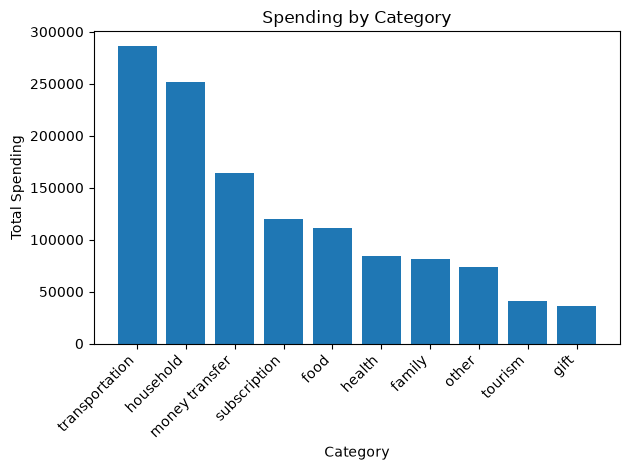

In [7]:
df=pd.DataFrame(result1)

plt.bar(df["category"],df["totalSpend"])
plt.xlabel("Category")
plt.ylabel("Total Spending")
plt.title("Spending by Category")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [8]:
Monthly_Income_vs_Expense=[{"$group":
                            {"_id":
                             {"year":{"$year":"$date"},
                              "month":{"$month":"$date"},
                              "type":"$income_expense"
                              },
                            "total":{"$sum":"$amount"}
                            }},{
                              "$sort": {
                                  "_id.year": 1,
                                  "_id.month": 1
                              }
                          }]
result2=list(collection.aggregate(Monthly_Income_vs_Expense))
print(result2)

[{'_id': {'year': 2015, 'month': 1, 'type': 'Expense'}, 'total': 8868.0}, {'_id': {'year': 2015, 'month': 2, 'type': 'Expense'}, 'total': 13420.0}, {'_id': {'year': 2015, 'month': 2, 'type': 'Income'}, 'total': 99612.0}, {'_id': {'year': 2015, 'month': 3, 'type': 'Expense'}, 'total': 13019.6}, {'_id': {'year': 2015, 'month': 3, 'type': 'Income'}, 'total': 141612.0}, {'_id': {'year': 2015, 'month': 4, 'type': 'Expense'}, 'total': 7582.0}, {'_id': {'year': 2015, 'month': 4, 'type': 'Income'}, 'total': 98612.0}, {'_id': {'year': 2015, 'month': 5, 'type': 'Expense'}, 'total': 42152.0}, {'_id': {'year': 2015, 'month': 5, 'type': 'Income'}, 'total': 95718.0}, {'_id': {'year': 2015, 'month': 6, 'type': 'Income'}, 'total': 95718.0}, {'_id': {'year': 2015, 'month': 6, 'type': 'Expense'}, 'total': 2396.0}, {'_id': {'year': 2015, 'month': 7, 'type': 'Expense'}, 'total': 5596.0}, {'_id': {'year': 2015, 'month': 7, 'type': 'Income'}, 'total': 95718.0}, {'_id': {'year': 2015, 'month': 8, 'type': 'In

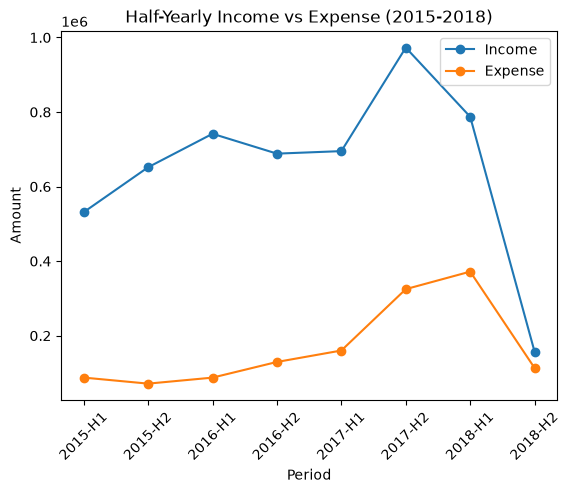

In [15]:
df=pd.DataFrame(result2)
df["year"]=df["_id"].apply(lambda x: x["year"])
df["month"]=df["_id"].apply(lambda x: x["month"])
df["type"]=df["_id"].apply(lambda x: x["type"])

df=df[df["year"].between(2015,2018)]

df["half"]=df["month"].apply(lambda x: "H1" if x<=6 else "H2")

half_yearly=df.groupby(["type","year","half"])["total"].sum().reset_index()
half_yearly["period_label"]=half_yearly["year"].astype(str)+"-"+half_yearly["half"]
half_yearly=half_yearly.sort_values(["year","half"])

income=half_yearly[half_yearly["type"]=="Income"]
expense=half_yearly[half_yearly["type"]=="Expense"]

plt.plot(income["period_label"], income["total"], label="Income",marker='o')
plt.plot(expense["period_label"], expense["total"], label="Expense",marker='o')

plt.xlabel("Period")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.title("Half-Yearly Income vs Expense (2015-2018)")
plt.legend()
plt.show()

In [27]:
spending_by_payment=[{"$match":{"income_expense":"Expense"}},{"$group":{"_id":"$mode","total":{"$sum":"$amount"}}},{"$sort":{"total":-1}},{"$project":{"_id":0,"mode":"$_id","total":1}},{"$limit":4}]
result3=list(collection.aggregate(spending_by_payment))
print(result3)

[{'total': 901276.96, 'mode': 'Saving Bank account 1'}, {'total': 275570.02, 'mode': 'Credit Card'}, {'total': 167524.96, 'mode': 'Cash'}, {'total': 962.72, 'mode': 'Debit Card'}]


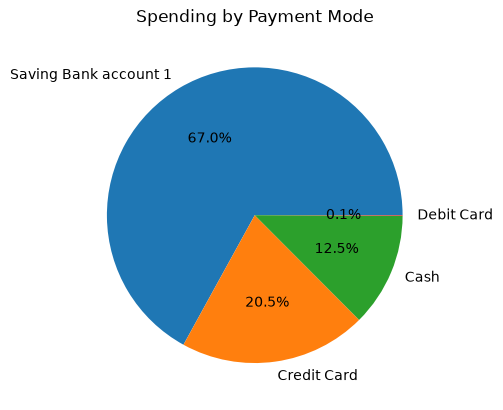

In [28]:
df=pd.DataFrame(result3)
plt.pie(df["total"],labels=df["mode"],autopct="%1.1f%%")
plt.title("Spending by Payment Mode")
plt.show()

In [20]:
category_statistics=[{"$match":{"income_expense":"Expense"}},{"$group":{"_id":"$category","total":{"$sum":"$amount"},"average":{"$avg":"$amount"},"highest":{"$max":"$amount"}}},{"$sort":{"total":-1,"average":-1,"highest":-1}},{"$limit":10}]
result4=list(collection.aggregate(category_statistics))
print(result4)

[{'_id': 'transportation', 'total': 286132.0, 'average': 718.9246231155779, 'highest': 50000.0}, {'_id': 'household', 'total': 251551.16, 'average': 990.3588976377953, 'highest': 21500.0}, {'_id': 'money transfer', 'total': 164046.0, 'average': 10252.875, 'highest': 30000.0}, {'_id': 'subscription', 'total': 119866.98, 'average': 758.6517721518987, 'highest': 28400.0}, {'_id': 'food', 'total': 111055.8, 'average': 107.61220930232558, 'highest': 2421.0}, {'_id': 'health', 'total': 84245.5, 'average': 810.0528846153846, 'highest': 22700.0}, {'_id': 'family', 'total': 81756.4, 'average': 997.0292682926829, 'highest': 5000.0}, {'_id': 'other', 'total': 73723.2, 'average': 519.1774647887323, 'highest': 4720.0}, {'_id': 'tourism', 'total': 41217.7, 'average': 5152.2125, 'highest': 20000.0}, {'_id': 'gift', 'total': 36002.0, 'average': 900.05, 'highest': 4800.0}]


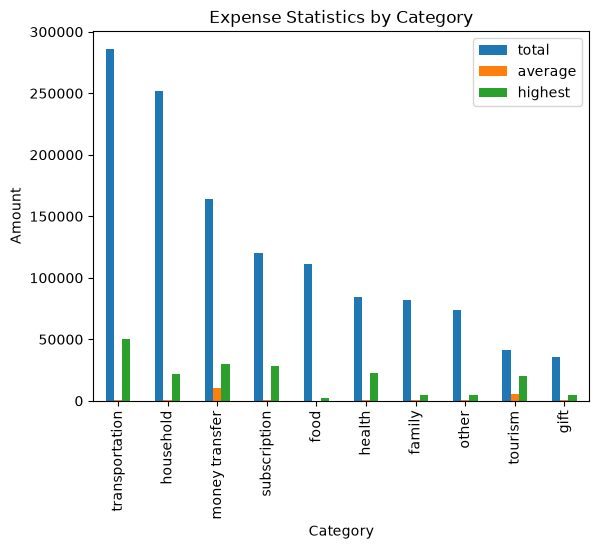

In [21]:
df=pd.DataFrame(result4)
df.plot(x="_id",y=["total","average","highest"],kind="bar")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.title("Expense Statistics by Category")
plt.show()

In [23]:
expense_distribution=[{"$match":{"income_expense":"Expense"}},{"$project":{"_id":0,"category":1,"amount":1}}]
result5=list(collection.aggregate(expense_distribution))
print(result5)

[{'category': 'transportation', 'amount': 30.0}, {'category': 'food', 'amount': 60.0}, {'category': 'subscription', 'amount': 19.0}, {'category': 'festivals', 'amount': 251.0}, {'category': 'subscription', 'amount': 200.0}, {'category': 'transportation', 'amount': 50.0}, {'category': 'transportation', 'amount': 40.0}, {'category': 'other', 'amount': 83.0}, {'category': 'food', 'amount': 46.0}, {'category': 'family', 'amount': 1000.0}, {'category': 'gift', 'amount': 118.0}, {'category': 'food', 'amount': 510.85}, {'category': 'food', 'amount': 36.0}, {'category': 'food', 'amount': 78.0}, {'category': 'household', 'amount': 343.0}, {'category': 'food', 'amount': 27.0}, {'category': 'food', 'amount': 15.0}, {'category': 'food', 'amount': 36.0}, {'category': 'food', 'amount': 40}, {'category': 'food', 'amount': 60.0}, {'category': 'food', 'amount': 45.0}, {'category': 'food', 'amount': 36.0}, {'category': 'apparel', 'amount': 91.0}, {'category': 'food', 'amount': 1120.0}, {'category': 'foo

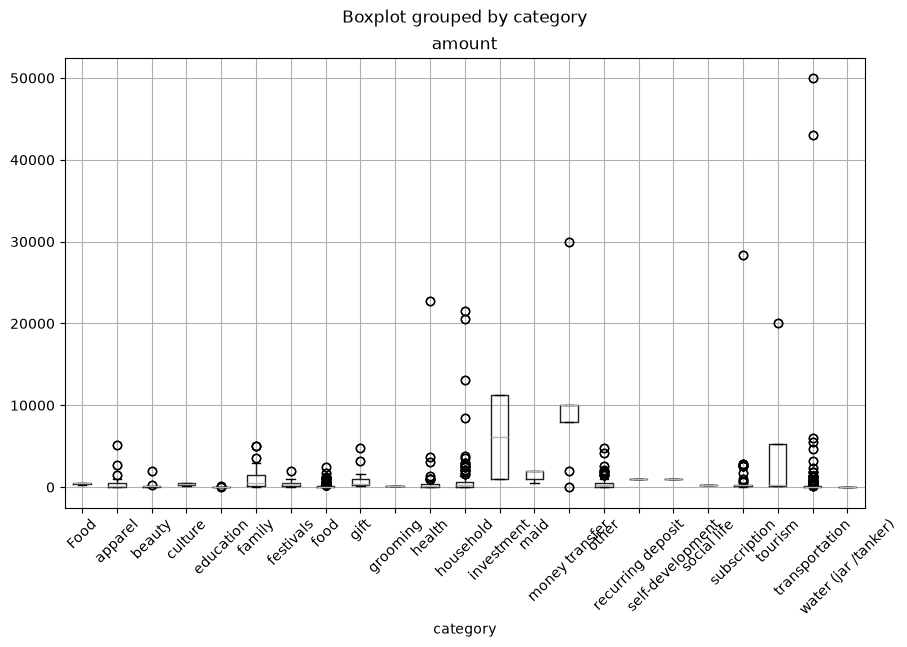

In [24]:
df=pd.DataFrame(result5)
df.boxplot(column="amount",by="category",figsize=(10,6))
plt.xticks(rotation=45)
plt.show()